# One Queue or Two

This notebook presents a case study from *Modeling and Simulation in Python*.  It explores a question related to queueing theory, which is the study of systems that involve waiting in lines, also known as "queues".

Suppose you are designing the checkout area for a new store.  There is room for two checkout counters and a waiting area for customers.  You can make two lines, one for each counter, or one line that serves both counters.

In theory, you might expect a single line to be better, but it has some practical drawbacks: in order to maintain a single line, you would have to install rope barriers, and customers might be put off by what seems to be a longer line, even if it moves faster.

So you'd like to check whether the single line is really better and by how much.  Simulation can help answer this question.

As we did in the bike share model, we'll assume that a customer is equally likely to arrive during any time step.  I'll denote this probability using the Greek letter lambda, $\lambda$, or the variable name `lam`.  The value of $\lambda$ probably varies from day to day, so we'll have to consider a range of possibilities.

Based on data from other stores, you know that it takes 5 minutes for a customer to check out, on average.  But checkout times are highly variable: most customers take less than 5 minutes, but some take substantially more.  A simple way to model this variability is to assume that when a customer is checking out, they have the same probability of finishing up during each time step.  I'll denote this probability using the Greek letter mu, $\mu$, or the variable name `mu`.

If we choose $\mu=1/5$, the average number of time steps for each checkout will be 5 minutes, which is consistent with the data.

## One server, one queue

Write a function called `make_system` that takes `lam` and `mu` as parameters and returns a `System` object with variables `lam`, `mu`, and `duration`.  Set `duration`, which is the number of time steps to simulate, to 10 hours, expressed in minutes.

In [34]:
# download modsim.py if necessary

from os.path import basename, exists

def download(url):
    filename = basename(url)
    if not exists(filename):
        from urllib.request import urlretrieve
        local, _ = urlretrieve(url, filename)
        print('Downloaded ' + local)

download('https://github.com/AllenDowney/ModSimPy/raw/master/modsim.py')

In [35]:
from modsim import *

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# The case study uses 10 hours of operating time.
# Chapter 4 introduces multiple simulation runs to reduce random noise.
NUM_REPLICATIONS = 10

In [36]:
def make_system(lam, mu):
    """Make a queueing System.

    lam: probability of a customer arriving during one minute
    mu: probability that a busy checkout finishes during one minute
    """
    system = System(
        lam=lam,
        mu=mu,
        duration=10 * 60
    )
    return system

Test this function by creating a `System` object with `lam=1/8` and `mu=1/5`.

In [37]:
# Test make_system with the parameter values specified in the template.

lam = 1 / 8
mu = 1 / 5

system = make_system(lam, mu)

print("System parameters:")
display(show(system))

assert system.lam == lam
assert system.mu == mu
assert system.duration == 600

System parameters:


,value
lam,0.125
mu,0.200
duration,600.000


Write an update function that takes as parameters `x`, which is the total number of customers in the store, including the one checking out; `t`, which is the number of minutes that have elapsed in the simulation, and `system`, which is a `System` object.

If there's a customer checking out, it should use `flip` to decide whether they are done.  And it should use `flip` to decide if a new customer has arrived.

It should return the total number of customers at the end of the time step.

In [38]:
def update_func(x, t, system):
    """Update a one-server, one-queue system for one minute.

    x: total customers in the store, including any customer in service
    t: elapsed time in minutes
    system: System containing lam and mu

    A customer in service may finish, then a new customer may arrive.
    """
    if x > 0 and flip(system.mu):
        x -= 1

    if flip(system.lam):
        x += 1

    return x

Test your function by calling it with `x=1`, `t=0`, and the `System` object you created.  If you run it a few times, you should see different results.

In [39]:
# Test the one-server update function several times.
# Different results are expected because arrivals and service are random.

np.random.seed(2026)

test_updates = [
    update_func(x=1, t=0, system=system)
    for _ in range(10)
]

print("Ten test updates from x=1:")
print(test_updates)

assert all(value >= 0 for value in test_updates)

Ten test updates from x=1:
[1, 2, 1, 0, 1, 1, 1, 0, 1, 1]


Now we can run the simulation.  Here's a version of `run_simulation` that creates a `TimeSeries` with the total number of customers in the store, including the one checking out.

In [40]:

def run_simulation_two_queues(system, update_func):
    """
    Simulate two separate queues for exactly system.duration minutes.
    Store initial state and every subsequent minute.
    """

    duration = int(system.duration)

    x1 = 0
    x2 = 0

    results1 = TimeSeries(name='Queue 1')
    results2 = TimeSeries(name='Queue 2')

    # Initial state
    results1[0] = x1
    results2[0] = x2

    # Exactly 600 simulation updates
    for t in range(duration):

        x1, x2 = update_func(x1, x2, t, system)

        results1[t + 1] = x1
        results2[t + 1] = x2

    # Validation
    assert len(results1) == duration + 1
    assert len(results2) == duration + 1

    assert results1.index[-1] == duration
    assert results2.index[-1] == duration

    assert results1.min() >= 0
    assert results2.min() >= 0

    return results1, results2


Call `run_simulation` with your update function and plot the results.

Simulation duration: 600
Number of recorded points: 601
Starting time: 0
Ending time: 600
Minimum queue length: 0

All simulation validation tests passed!


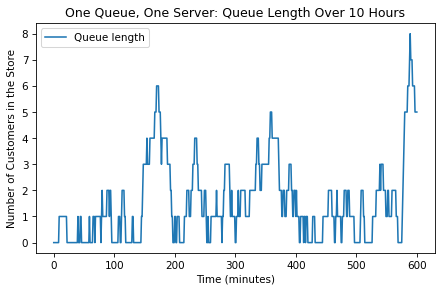

In [41]:

# Run one representative simulation for one queue and one server.

np.random.seed(20261031)

plt.figure()

results = run_simulation(system, update_func)

results.plot()

decorate(
    title='One Queue, One Server: Queue Length Over 10 Hours',
    xlabel='Time (minutes)',
    ylabel='Number of Customers in the Store'
)

# Display simulation validation information

print("Simulation duration:", system.duration)
print("Number of recorded points:", len(results))
print("Starting time:", results.index[0])
print("Ending time:", results.index[-1])
print("Minimum queue length:", results.min())

# Validation checks

assert len(results) == int(system.duration) + 1
assert results.index[0] == 0
assert results.index[-1] == int(system.duration)
assert results.min() >= 0

print("\nAll simulation validation tests passed!")


After the simulation, we can compute `L`, which is the average number of customers in the system, and `W`, which is the average time customers spend in the store.  `L` and `W` are related by Little's Law:

$L = \lambda W$

Where $\lambda$ is the arrival rate.  Here's a function that computes them.

In [42]:
def compute_metrics(results, system):
    """Compute average number of customers and wait time.

    results: TimeSeries of queue lengths
    system: System object

    returns: L, W
    """
    L = results.mean()
    W = L / system.lam
    return L, W

Call `compute_metrics` with the results from your simulation.

In [43]:
# Compute L and W for the representative one-server simulation.

L, W = compute_metrics(results, system)

print(f"Average number of customers in the system (L): {L:.3f}")
print(f"Average time in the store (W): {W:.3f} minutes")

print("\nLittle's Law:")
print(f"L = lambda * W = {system.lam:.3f} * {W:.3f} = {system.lam * W:.3f}")

Average number of customers in the system (L): 1.557
Average time in the store (W): 12.459 minutes

Little's Law:
L = lambda * W = 0.125 * 12.459 = 1.557


### Parameter sweep

Since we don't know the actual value of $\lambda$, we can sweep through a range of possibilities, from 10% to 80% of the completion rate, $\mu$.  (If customers arrive faster than the completion rate, the queue grows without bound.  In that case the metrics `L` and `W` just depend on how long the store is open.)

Create an array of values for `lam`.

In [44]:
# Chapter 10 specifies an arrival-rate sweep from 10% to 80% of mu.
# Eight evenly spaced values preserve the same 0.02 increments used
# in the two-server common-load comparison.

lam_array = np.round(
    linspace(0.1 * mu, 0.8 * mu, 8),
    6
)

print("One-server arrival probabilities per minute:")
print(lam_array)

One-server arrival probabilities per minute:
[0.02 0.04 0.06 0.08 0.1  0.12 0.14 0.16]


Write a function that takes an array of values for `lam`, a single value for `mu`, and an update function.

For each value of `lam`, it should run a simulation, compute `L` and `W`, and store the value of `W` in a `SweepSeries`.

It should return the `SweepSeries`.

In [45]:
def sweep_lam(lam_array, mu, update_func, num_runs=NUM_REPLICATIONS):
    """Run repeated simulations for each arrival probability.

    For each lambda, run the queue model num_runs times, compute
    L and W for every run, and store the mean W in a SweepSeries.

    This follows the multiple-run parameter-sweep approach
    introduced in Chapter 4.
    """
    sweep = SweepSeries()

    for lam_value in lam_array:
        system = make_system(lam=lam_value, mu=mu)
        replication_wait_times = TimeSeries()

        for run_number in range(num_runs):
            run_results = run_simulation(system, update_func)
            L, W = compute_metrics(run_results, system)
            replication_wait_times[run_number] = W

        sweep[lam_value] = replication_wait_times.mean()

    return sweep

Call your function to generate a `SweepSeries`, and plot it.

Scenario 1 sweep completed.


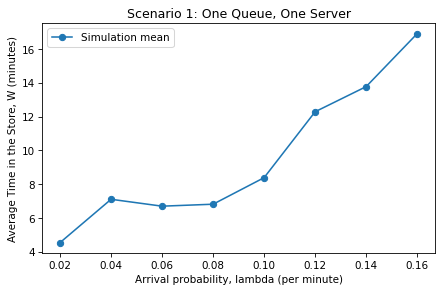

In [46]:
# Scenario 1: one queue and one server.
# Average 10 replications at each lambda.

np.random.seed(20261031)

plt.figure()

sweep_series = sweep_lam(
    lam_array,
    mu,
    update_func,
    num_runs=NUM_REPLICATIONS
)

sweep_series.plot(
    style='o-',
    label='Simulation mean'
)

decorate(
    title='Scenario 1: One Queue, One Server',
    xlabel='Arrival probability, lambda (per minute)',
    ylabel='Average Time in the Store, W (minutes)'
)

print("Scenario 1 sweep completed.")

In [47]:
# Display the Scenario 1 parameter sweep results.

single_server_sweep = sweep_series.copy()
single_server_sweep.name = "Mean time in store (minutes)"

single_server_results = single_server_sweep.to_frame()
single_server_results.index.name = "Arrival probability (lambda)"

display(single_server_results.round(3))
print(f"Mean W across the Scenario 1 lambda sweep: {single_server_sweep.mean():.3f} minutes")
print(f"Number of lambda values: {len(single_server_sweep)}")
print(f"Replications per lambda: {NUM_REPLICATIONS}")

,Mean time in store (minutes)
Arrival probability (lambda),
0.02,4.551
0.04,7.113
0.06,6.705
0.08,6.822
0.10,8.393
0.12,12.292
0.14,13.778
0.16,16.910


Mean W across the Scenario 1 lambda sweep: 9.571 minutes
Number of lambda values: 8
Replications per lambda: 10


If we imagine that this range of values represents arrival rates on different days, we can use the average value of `W`, for a range of values of `lam`, to compare different queueing strategies.

In [48]:
# Calculate the average W for Scenario 1.
# This summarizes the range of arrival probabilities specified
# for the one-server system.

single_server_average_W = float(single_server_sweep.mean())

print(
    "Scenario 1 average time in the store across the tested "
    f"arrival-rate range: {single_server_average_W:.3f} minutes"
)
print(
    "Arrival-rate range: "
    f"{lam_array.min():.3f} to {lam_array.max():.3f} per minute"
)

Scenario 1 average time in the store across the tested arrival-rate range: 9.571 minutes
Arrival-rate range: 0.020 to 0.160 per minute


### Analysis

The model I chose for this system is a common model in queueing theory, in part because many of its properties can be derived analytically.

In particular, we can derive the average time in the store as a function of $\mu$ and $\lambda$:

$W = 1 / (\mu - \lambda)$

The following function plots the theoretical value of $W$ as a function of $\lambda$.

In [49]:
def plot_W(lam_array, mu):
    """Plot the theoretical mean wait time.

    lam_array: array of values for `lam`
    mu: probability of finishing a checkout
    """
    W_array = 1 / (mu - lam_array)
    W_series = make_series(lam_array, W_array)
    W_series.plot(style='-', label='analysis')

Use this function to plot the theoretical results, then plot your simulation results again on the same graph.  How do they compare?

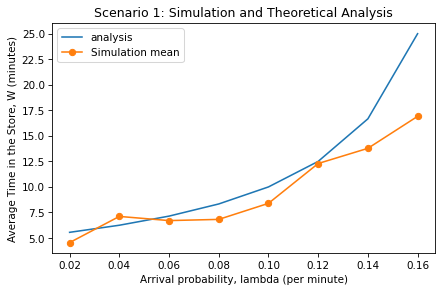

In [50]:
# Compare the simulation sweep with the theoretical relation
# W = 1 / (mu - lambda), given in the Chapter 10 case study.

plt.figure()

plot_W(lam_array, mu)

single_server_sweep.plot(
    style='o-',
    label='Simulation mean'
)

decorate(
    title='Scenario 1: Simulation and Theoretical Analysis',
    xlabel='Arrival probability, lambda (per minute)',
    ylabel='Average Time in the Store, W (minutes)'
)

plt.show()

## Multiple servers

Now let's try the other two queueing strategies:

1.  One queue with two checkout counters.
2.  Two queues, one for each counter.

The following figure shows the three scenarios:

![One queue, one server (left), one queue, two servers (middle), two queues, two servers (right).](https://github.com/AllenDowney/ModSim/raw/main/figs/queue.png)

Write an update function for one queue with two servers.

In [51]:
def update_func_two_servers(x, t, system):
    """Update one queue served by two checkout counters.

    x: total customers in the system, including customers in service
    t: elapsed time in minutes
    system: System containing lam and mu

    At most two customers can be in service at the start of a time step.
    Each busy server independently finishes with probability mu.
    """
    busy_servers = min(x, 2)
    completed = 0

    for _ in range(busy_servers):
        if flip(system.mu):
            completed += 1

    x -= completed

    if flip(system.lam):
        x += 1

    return x

Use this update function to simulate the system, plot the results, and print the metrics.

Arrival probability (lambda): 0.250
Service probability per server (mu): 0.200
Average number in the system (L): 2.042
Average time in the store (W): 8.166 minutes


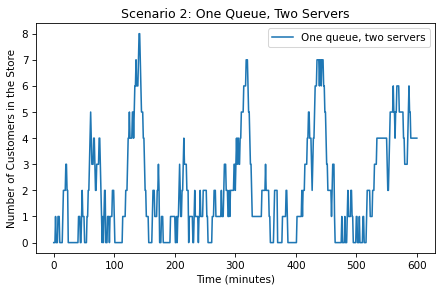

In [52]:
# Scenario 2: one shared queue with two checkout servers.
# Use lambda=0.25, which is greater than mu=0.20 but below
# the combined nominal service rate of two servers.

system_two_servers = make_system(
    lam=0.25,
    mu=mu
)

np.random.seed(20261032)

plt.figure()

results_two_servers = run_simulation(
    system_two_servers,
    update_func_two_servers
)

L_two_servers, W_two_servers = compute_metrics(
    results_two_servers,
    system_two_servers
)

results_two_servers.plot(label='One queue, two servers')

decorate(
    title='Scenario 2: One Queue, Two Servers',
    xlabel='Time (minutes)',
    ylabel='Number of Customers in the Store'
)

print(f"Arrival probability (lambda): {system_two_servers.lam:.3f}")
print(f"Service probability per server (mu): {system_two_servers.mu:.3f}")
print(f"Average number in the system (L): {L_two_servers:.3f}")
print(f"Average time in the store (W): {W_two_servers:.3f} minutes")

assert results_two_servers.min() >= 0

Since we have two checkout counters now, we can consider values for $\lambda$ that exceed $\mu$.

Create a new array of values for `lam` from 10% to 160% of `mu`.

In [53]:
# Chapter 10 specifies an arrival-rate sweep from 10% to 160% of mu
# for systems with two checkout counters.

lam_array_two = np.round(
    linspace(0.1 * mu, 1.6 * mu, 16),
    6
)

print("Two-server arrival probabilities per minute:")
print(lam_array_two)
print(
    "Maximum tested arrival probability:",
    f"{lam_array_two.max():.3f}"
)
print(
    "Combined nominal service capacity:",
    f"{2 * mu:.3f}",
    "customers per minute"
)

Two-server arrival probabilities per minute:
[0.02 0.04 0.06 0.08 0.1  0.12 0.14 0.16 0.18 0.2  0.22 0.24 0.26 0.28
 0.3  0.32]
Maximum tested arrival probability: 0.320
Combined nominal service capacity: 0.400 customers per minute


Use your sweep function to simulate the two server, one queue scenario with a range of values for `lam`.

Plot the results and print the average value of `W` across all values of `lam`.

Scenario 2 parameter sweep completed.


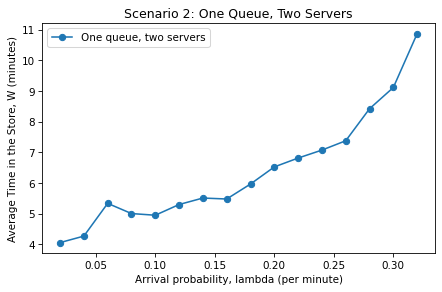

In [54]:
# Sweep Scenario 2: one queue with two servers.

np.random.seed(20261033)

plt.figure()

sweep_two_servers = sweep_lam(
    lam_array_two,
    mu,
    update_func_two_servers,
    num_runs=NUM_REPLICATIONS
)

sweep_two_servers.plot(
    style='o-',
    label='One queue, two servers'
)

decorate(
    title='Scenario 2: One Queue, Two Servers',
    xlabel='Arrival probability, lambda (per minute)',
    ylabel='Average Time in the Store, W (minutes)'
)

print("Scenario 2 parameter sweep completed.")

In [55]:
# Display and summarize Scenario 2.

two_server_one_queue_sweep = sweep_two_servers.copy()
two_server_one_queue_sweep.name = "Mean time in store (minutes)"

two_server_one_queue_results = (
    two_server_one_queue_sweep.to_frame()
)

two_server_one_queue_results.index.name = (
    "Arrival probability (lambda)"
)

display(two_server_one_queue_results.round(3))

two_server_average_W = float(
    two_server_one_queue_sweep.mean()
)

print(
    "Mean W across the Scenario 2 lambda sweep: "
    f"{two_server_average_W:.3f} minutes"
)
print(f"Replications per lambda: {NUM_REPLICATIONS}")

,Mean time in store (minutes)
Arrival probability (lambda),
0.02,4.060
0.04,4.272
0.06,5.338
0.08,5.006
0.10,4.952
0.12,5.301
0.14,5.512
0.16,5.480
0.18,5.969


Mean W across the Scenario 2 lambda sweep: 6.381 minutes
Replications per lambda: 10


## Multiple queues

To simulate the scenario with two separate queues, we need two state variables to keep track of customers in each queue.

Write an update function that takes `x1`, `x2`, `t`, and `system` as parameters and returns `x1` and `x2` as return values.  If you are not sure how to return more than one return value, see `compute_metrics`.

When a customer arrives, which queue do they join?

In [56]:
def update_func_two_queues(x1, x2, t, system):
    """Update two independent queues, each with one server.

    x1: customers in queue/system 1, including any customer in service
    x2: customers in queue/system 2, including any customer in service
    t: elapsed time in minutes
    system: System containing lam and mu

    Each busy server may finish independently. A new arrival chooses
    either queue with equal probability (0.5).
    """
    if x1 > 0 and flip(system.mu):
        x1 -= 1

    if x2 > 0 and flip(system.mu):
        x2 -= 1

    if flip(system.lam):
        if flip(0.5):
            x1 += 1
        else:
            x2 += 1

    return x1, x2

Write a version of `run_simulation` that works with this update function.

In [57]:
def run_simulation_two_queues(system, update_func):
    """Simulate two separate queues and return both queue-length series."""
    x1 = 0
    x2 = 0

    results1 = TimeSeries(name='Queue 1')
    results2 = TimeSeries(name='Queue 2')

    results1[0] = x1
    results2[0] = x2

    for t in linrange(0, system.duration):
        x1, x2 = update_func(x1, x2, t, system)

        results1[t + 1] = x1
        results2[t + 1] = x2

    return results1, results2

Test your functions by running a simulation with a single value of `lam`.

Arrival probability (lambda): 0.250
Service probability per server (mu): 0.200
Average total number in the system (L): 2.960
Average time in the store (W): 11.841 minutes


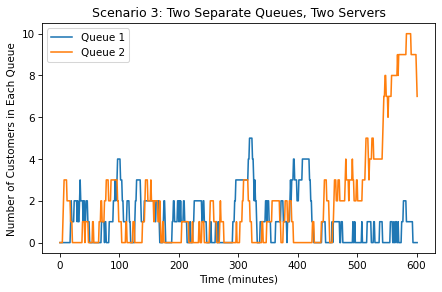

In [58]:
# Scenario 3: two separate queues with one server per queue.
# Both queues receive customers from a common arrival stream,
# with every new customer randomly assigned to either queue.

system_two_queues = make_system(
    lam=0.25,
    mu=mu
)

np.random.seed(20261034)

results_queue1, results_queue2 = run_simulation_two_queues(
    system_two_queues,
    update_func_two_queues
)

# Little's Law applies to the combined two-queue system.
total_results_two_queues = results_queue1 + results_queue2
L_two_queues = total_results_two_queues.mean()
W_two_queues = L_two_queues / system_two_queues.lam

plt.figure()
results_queue1.plot(label='Queue 1')
results_queue2.plot(label='Queue 2')

decorate(
    title='Scenario 3: Two Separate Queues, Two Servers',
    xlabel='Time (minutes)',
    ylabel='Number of Customers in Each Queue'
)

print(f"Arrival probability (lambda): {system_two_queues.lam:.3f}")
print(f"Service probability per server (mu): {system_two_queues.mu:.3f}")
print(f"Average total number in the system (L): {L_two_queues:.3f}")
print(f"Average time in the store (W): {W_two_queues:.3f} minutes")

assert results_queue1.min() >= 0
assert results_queue2.min() >= 0

Sweep a range of values for `lam`, plot the results, and print the average wait time across all values of `lam`.

How do the results compare to the scenario with two servers and one queue?

In [59]:
def sweep_lam_two_queues(
    lam_array,
    mu,
    update_func,
    num_runs=NUM_REPLICATIONS
):
    """Sweep arrival probabilities for the two-queue system.

    For each lambda, repeated simulations are performed. The total
    queue length is used to compute L, and W is computed using
    Little's Law for the combined system.
    """
    sweep = SweepSeries()

    for lam_value in lam_array:
        system = make_system(lam=lam_value, mu=mu)
        replication_wait_times = TimeSeries()

        for run_number in range(num_runs):
            results1, results2 = run_simulation_two_queues(
                system,
                update_func
            )

            total_results = results1 + results2
            L = total_results.mean()
            W = L / system.lam

            replication_wait_times[run_number] = W

        sweep[lam_value] = replication_wait_times.mean()

    return sweep

,Mean time in store (minutes)
Parameter,
0.02,6.063
0.04,5.311
0.06,5.136
0.08,6.277
0.10,6.601
0.12,7.525
0.14,6.881
0.16,7.962
0.18,7.499


Scenario 3 parameter sweep completed.
Replications per lambda: 10


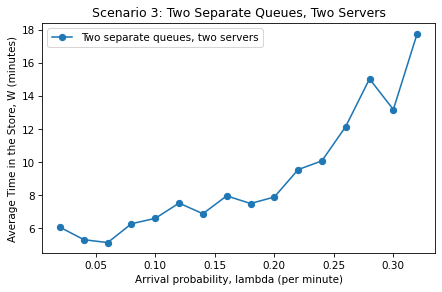

In [60]:
# Sweep Scenario 3 over the same extended lambda range as Scenario 2.

np.random.seed(20261035)

sweep_two_queues = sweep_lam_two_queues(
    lam_array_two,
    mu,
    update_func_two_queues,
    num_runs=NUM_REPLICATIONS
)

two_queues_two_servers_sweep = sweep_two_queues.copy()
two_queues_two_servers_sweep.name = "Mean time in store (minutes)"

plt.figure()

two_queues_two_servers_sweep.plot(
    style='o-',
    label='Two separate queues, two servers'
)

decorate(
    title='Scenario 3: Two Separate Queues, Two Servers',
    xlabel='Arrival probability, lambda (per minute)',
    ylabel='Average Time in the Store, W (minutes)'
)

display(
    two_queues_two_servers_sweep
    .to_frame()
    .round(3)
)

print("Scenario 3 parameter sweep completed.")
print(f"Replications per lambda: {NUM_REPLICATIONS}")

In [61]:
# ============================================================
# FINAL COMPARISON OF THE THREE QUEUEING STRATEGIES
# ============================================================

# Common lambda range: 10%-80% of mu.
# This range is stable for all three strategies and provides
# a fair like-for-like comparison.

common_comparison = pd.DataFrame({
    'One queue, one server': single_server_sweep.reindex(lam_array),
    'One queue, two servers': two_server_one_queue_sweep.reindex(lam_array),
    'Two queues, two servers': two_queues_two_servers_sweep.reindex(lam_array)
})

common_comparison.index.name = 'Arrival probability (lambda)'

print("Comparison over the common lambda range (10%-80% of mu):")
display(common_comparison.round(3))

common_range_means = common_comparison.mean()

print("\nMean W over the common lambda range:")
display(common_range_means.to_frame("Mean time in store (minutes)").round(3))

# Full ranges required by the case-study instructions.
scenario_summary = pd.DataFrame({
    'Scenario': [
        'One queue, one server',
        'One queue, two servers',
        'Two queues, two servers'
    ],
    'Arrival probability range': [
        f"{lam_array.min():.3f} to {lam_array.max():.3f}",
        f"{lam_array_two.min():.3f} to {lam_array_two.max():.3f}",
        f"{lam_array_two.min():.3f} to {lam_array_two.max():.3f}"
    ],
    'Mean W over tested range (minutes)': [
        single_server_sweep.mean(),
        two_server_one_queue_sweep.mean(),
        two_queues_two_servers_sweep.mean()
    ],
    'Mean W over common range (minutes)': [
        common_range_means['One queue, one server'],
        common_range_means['One queue, two servers'],
        common_range_means['Two queues, two servers']
    ]
})

print("\nOverall scenario summary:")
display(scenario_summary.round(3))

print("\nInterpretation:")
best_common_layout = common_range_means.idxmin()
print(
    f"Lowest average time in the store over the common load range: "
    f"{best_common_layout}"
)

print(
    "The two-server strategies are also compared over the full "
    "10%-160% of mu range. The single-server range is narrower "
    "because its arrival probability must remain below its single-server "
    "service probability for a stable queue."
)

Comparison over the common lambda range (10%-80% of mu):


,"One queue, one server","One queue, two servers","Two queues, two servers"
Arrival probability (lambda),,,
0.02,4.551,4.060,6.063
0.04,7.113,4.272,5.311
0.06,6.705,5.338,5.136
0.08,6.822,5.006,6.277
0.10,8.393,4.952,6.601
0.12,12.292,5.301,7.525
0.14,13.778,5.512,6.881
0.16,16.910,5.480,7.962



Mean W over the common lambda range:


,Mean time in store (minutes)
"One queue, one server",9.571
"One queue, two servers",4.990
"Two queues, two servers",6.470



Overall scenario summary:


,Scenario,Arrival probability range,Mean W over tested range (minutes),Mean W over common range (minutes)
0,"One queue, one server",0.020 to 0.160,9.571,9.571
1,"One queue, two servers",0.020 to 0.320,6.381,4.990
2,"Two queues, two servers",0.020 to 0.320,9.057,6.470



Interpretation:
Lowest average time in the store over the common load range: One queue, two servers
The two-server strategies are also compared over the full 10%-160% of mu range. The single-server range is narrower because its arrival probability must remain below its single-server service probability for a stable queue.


## Report generation

The next cell generates a PDF report directly from the simulation results. It includes the three queue configurations, parameter ranges, comparison tables, plots, theoretical one-server analysis, real-world applications, and model limitations.

**Course alignment:** `flip` and `TimeSeries` (Chapter 2), metrics (Chapter 3), `linspace`, `SweepSeries`, and repeated simulations (Chapter 4), `System` objects (Chapter 6), and the queueing case study (Chapter 10). The PDF export utility is only used to produce the report; it does not introduce an additional queueing model.

In [62]:

# ============================================================
# GENERATE THE QUEUEING SYSTEM PDF REPORT
# ============================================================

from matplotlib.backends.backend_pdf import PdfPages

report_dir = Path("Queueing_System_Report_Files")
report_dir.mkdir(parents=True, exist_ok=True)

pdf_path = report_dir / "Queueing_System_Report.pdf"

# Save the main comparison tables as CSV files.
scenario_summary.to_csv(report_dir / "Scenario_Summary.csv", index=False)
common_comparison.to_csv(report_dir / "Common_Load_Comparison.csv")
single_server_sweep.to_csv(report_dir / "One_Queue_One_Server_Sweep.csv")
two_server_one_queue_sweep.to_csv(report_dir / "One_Queue_Two_Servers_Sweep.csv")
two_queues_two_servers_sweep.to_csv(report_dir / "Two_Queues_Two_Servers_Sweep.csv")

# Prepare the theoretical single-server reference curve.
theoretical_W = make_series(
    lam_array,
    1 / (mu - lam_array),
    name="Theoretical W (minutes)"
)

with PdfPages(pdf_path) as pdf:

    # --------------------------------------------------------
    # PAGE 1: INTRODUCTION AND EXECUTIVE SUMMARY
    # --------------------------------------------------------
    fig = plt.figure(figsize=(8.27, 11.69))

    fig.text(
        0.08, 0.93,
        "QUEUEING SYSTEM: ONE QUEUE OR TWO",
        fontsize=20,
        fontweight="bold"
    )
    fig.text(
        0.08, 0.885,
        "ENG502 - Chapter 10 Case Study",
        fontsize=13
    )

    fig.text(
        0.08, 0.81,
        "1. Introduction and Objective",
        fontsize=14,
        fontweight="bold"
    )

    introduction = (
        "This case study uses simulation to compare three checkout "
        "layouts for a store with two checkout counters: (1) one queue "
        "with one server, (2) one shared queue with two servers, and "
        "(3) two separate queues with one server each.\n\n"
        "The objective is to compare the average number of customers "
        "in the system (L) and the average time customers spend in the "
        "store (W). Little's Law, L = lambda * W, is used to compute W."
    )

    fig.text(
        0.08, 0.76,
        introduction,
        fontsize=10.5,
        va="top",
        wrap=True
    )

    fig.text(
        0.08, 0.57,
        "2. Executive Summary",
        fontsize=14,
        fontweight="bold"
    )

    common_best_name = common_range_means.idxmin()
    common_best_value = float(common_range_means.min())

    summary_text = (
        f"Simulation duration: {system.duration} minutes (10 hours)\n\n"
        f"Service completion probability per busy server (mu): {mu:.3f} per minute\n\n"
        f"Replications per arrival-rate value: {NUM_REPLICATIONS}\n\n"
        f"Common comparison range: {lam_array.min():.3f} to {lam_array.max():.3f} arrivals per minute\n\n"
        f"Lowest mean W over the common range: {common_best_name}\n"
        f"Mean W for this strategy: {common_best_value:.3f} minutes\n\n"
        "The full two-server comparison also tests arrival probabilities "
        "up to 1.6 times mu. The one-server scenario uses the narrower "
        "10%-80% range specified in the case study."
    )

    fig.text(
        0.08, 0.52,
        summary_text,
        fontsize=10.5,
        va="top",
        wrap=True
    )

    fig.text(
        0.08, 0.13,
        "Key question: Does a single shared line reduce customer time "
        "in the store compared with two separate lines?",
        fontsize=10,
        style="italic",
        wrap=True
    )

    pdf.savefig(fig)
    plt.close(fig)

    # --------------------------------------------------------
    # PAGE 2: COURSE CONCEPTS AND EXPERIMENT DESIGN
    # --------------------------------------------------------
    fig = plt.figure(figsize=(8.27, 11.69))

    fig.text(
        0.08, 0.93,
        "3. Course Concepts and Experiment Design",
        fontsize=15,
        fontweight="bold"
    )

    course_text = (
        "COURSE CONCEPTS\n\n"
        "Chapter 2: Random events are represented using flip; "
        "simulation states are recorded in TimeSeries objects.\n\n"
        "Chapter 3: Metrics are used to quantify system performance.\n\n"
        "Chapter 4: linspace creates parameter values, SweepSeries "
        "stores parameter-sweep results, and repeated simulations "
        "are averaged to reduce random variation.\n\n"
        "Chapter 6: System objects store model parameters such as "
        "lambda, mu, and duration.\n\n"
        "Chapter 10: The One Queue or Two case study defines the "
        "three checkout configurations and the theoretical "
        "single-server relationship W = 1 / (mu - lambda).\n\n"
        "MODEL PARAMETERS AND TEST SCENARIOS\n\n"
        f"Service completion probability per busy server: mu = {mu:.3f} per minute.\n"
        f"Simulation duration: {system.duration} minutes (10 hours).\n"
        f"Replications for each lambda value: {NUM_REPLICATIONS}.\n\n"
        "Scenario 1 - One queue, one server:\n"
        f"lambda = {lam_array.min():.3f} to {lam_array.max():.3f} per minute.\n"
        "This range is 10%-80% of mu, as directed by the template.\n\n"
        "Scenario 2 - One queue, two servers:\n"
        f"lambda = {lam_array_two.min():.3f} to {lam_array_two.max():.3f} per minute.\n"
        "This range is 10%-160% of mu, as directed by the template.\n\n"
        "Scenario 3 - Two queues, two servers:\n"
        f"lambda = {lam_array_two.min():.3f} to {lam_array_two.max():.3f} per minute.\n"
        "The same extended arrival range is used for comparison with Scenario 2."
    )

    fig.text(
        0.08, 0.86,
        course_text,
        fontsize=9.6,
        va="top",
        wrap=True
    )

    fig.text(
        0.08, 0.09,
        "Modeling assumption: In the two-separate-queues scenario, "
        "each new arrival chooses either queue with equal probability (0.5).",
        fontsize=9,
        style="italic",
        wrap=True
    )

    pdf.savefig(fig)
    plt.close(fig)

    # --------------------------------------------------------
    # PAGE 3: RESULTS TABLE AND SCENARIO COMPARISON GRAPH
    # --------------------------------------------------------
    fig = plt.figure(figsize=(8.27, 11.69))

    fig.text(
        0.08, 0.93,
        "4. Results and Scenario Comparison",
        fontsize=15,
        fontweight="bold"
    )

    fig.text(
        0.08, 0.86,
        "Table 1. Mean time in the store across each scenario's tested range",
        fontsize=10.5,
        fontweight="bold"
    )

    summary_for_table = scenario_summary.rename(columns={
        'Arrival probability range': 'Lambda range (/min)',
        'Mean W over tested range (minutes)': 'Mean W full range (min)',
        'Mean W over common range (minutes)': 'Mean W common range (min)'
    }).copy()
    summary_for_table['Mean W full range (min)'] = (
        summary_for_table['Mean W full range (min)'].map(lambda value: f"{value:.3f}")
    )
    summary_for_table['Mean W common range (min)'] = (
        summary_for_table['Mean W common range (min)'].map(lambda value: f"{value:.3f}")
    )

    ax1 = fig.add_axes([0.05, 0.62, 0.90, 0.19])
    ax1.axis("off")

    table1 = ax1.table(
        cellText=summary_for_table.values,
        colLabels=summary_for_table.columns,
        cellLoc="center",
        loc="center"
    )
    table1.auto_set_font_size(False)
    table1.set_fontsize(7.2)
    table1.scale(1, 1.7)

    fig.text(
        0.08, 0.54,
        "Figure 1. Mean W over the common arrival-rate range",
        fontsize=10.5,
        fontweight="bold"
    )

    ax2 = fig.add_axes([0.12, 0.20, 0.78, 0.30])

    common_comparison.plot(
        ax=ax2,
        marker="o"
    )

    ax2.set_xlabel("Arrival probability, lambda (per minute)")
    ax2.set_ylabel("Average time in the store, W (minutes)")
    ax2.grid(True)
    ax2.legend(fontsize=8)

    fig.savefig(
        report_dir / "Figure_1_Common_Range_Comparison.png",
        dpi=200,
        bbox_inches="tight"
    )

    fig.text(
        0.08, 0.10,
        "The common-range comparison uses identical lambda values "
        "for all three layouts. This avoids comparing the one-server "
        "system's narrower load range directly with the extended "
        "two-server load range.",
        fontsize=8.5,
        wrap=True
    )

    pdf.savefig(fig)
    plt.close(fig)

    # --------------------------------------------------------
    # PAGE 4: THEORETICAL ANALYSIS FOR ONE SERVER
    # --------------------------------------------------------
    fig, ax = plt.subplots(figsize=(8.27, 11.69))

    ax.plot(
        theoretical_W.index,
        theoretical_W.values,
        marker="o",
        label="Theoretical analysis: W = 1 / (mu - lambda)"
    )

    ax.plot(
        single_server_sweep.index,
        single_server_sweep.values,
        marker="s",
        label="Simulation mean"
    )

    ax.set_title(
        "Scenario 1: Simulation Compared with Theoretical Analysis",
        fontsize=13
    )
    ax.set_xlabel("Arrival probability, lambda (per minute)")
    ax.set_ylabel("Average time in the store, W (minutes)")
    ax.grid(True)
    ax.legend(fontsize=8)

    fig.text(
        0.10, 0.07,
        "The theoretical relationship is the one-server analysis "
        "provided in the Chapter 10 case study. Simulation values "
        "may differ because the model uses discrete one-minute "
        "steps and finite repeated runs.",
        fontsize=9,
        wrap=True
    )

    fig.tight_layout(rect=[0.06, 0.12, 0.96, 0.94])
    pdf.savefig(fig)
    fig.savefig(
        report_dir / "Figure_2_One_Server_Theory_Comparison.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.close(fig)

    # --------------------------------------------------------
    # PAGE 5: REPRESENTATIVE QUEUE TRAJECTORIES
    # --------------------------------------------------------

    # Run all three layouts at the same arrival probability
    # so the representative trajectories are directly comparable.
    trajectory_lam = 0.12
    trajectory_system = make_system(
        lam=trajectory_lam,
        mu=mu
    )

    np.random.seed(20261036)
    trajectory_one_server = run_simulation(
        trajectory_system,
        update_func
    )

    np.random.seed(20261037)
    trajectory_shared_two_servers = run_simulation(
        trajectory_system,
        update_func_two_servers
    )

    np.random.seed(20261038)
    trajectory_queue1, trajectory_queue2 = run_simulation_two_queues(
        trajectory_system,
        update_func_two_queues
    )

    trajectory_two_separate_queues = (
        trajectory_queue1 + trajectory_queue2
    )

    fig, ax = plt.subplots(figsize=(8.27, 11.69))

    ax.plot(
        trajectory_one_server.index,
        trajectory_one_server.values,
        label="One queue, one server"
    )

    ax.plot(
        trajectory_shared_two_servers.index,
        trajectory_shared_two_servers.values,
        label="One queue, two servers"
    )

    ax.plot(
        trajectory_two_separate_queues.index,
        trajectory_two_separate_queues.values,
        label="Two queues, two servers (combined)"
    )

    ax.set_title(
        "Representative Queue-Length Trajectories",
        fontsize=14
    )
    ax.set_xlabel("Time (minutes)")
    ax.set_ylabel("Total customers in the system")
    ax.grid(True)
    ax.legend(fontsize=8)

    fig.text(
        0.10, 0.07,
        "Figure 3. Representative 10-hour trajectories for all three "
        f"layouts at the same arrival probability (lambda = {trajectory_lam:.2f} "
        "per minute). These are individual stochastic runs; the "
        "parameter-sweep results above are averages over "
        f"{NUM_REPLICATIONS} replications per lambda value.",
        fontsize=9,
        wrap=True
    )

    fig.tight_layout(rect=[0.06, 0.12, 0.96, 0.94])
    pdf.savefig(fig)
    fig.savefig(
        report_dir / "Figure_3_Representative_Queue_Trajectories.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.close(fig)

    # --------------------------------------------------------
    # PAGE 6: ANALYSIS, APPLICATIONS, LIMITATIONS, CONCLUSION
    # --------------------------------------------------------
    fig = plt.figure(figsize=(8.27, 11.69))

    fig.text(
        0.08, 0.93,
        "5. Analysis, Applications and Conclusion",
        fontsize=15,
        fontweight="bold"
    )

    common_table_text = (
        f"One queue, one server: "
        f"{common_range_means['One queue, one server']:.3f} minutes\n"
        f"One queue, two servers: "
        f"{common_range_means['One queue, two servers']:.3f} minutes\n"
        f"Two queues, two servers: "
        f"{common_range_means['Two queues, two servers']:.3f} minutes"
    )

    analysis = (
        "ANALYSIS OF RESULTS\n\n"
        "The common-range comparison evaluates all three designs "
        "using the same lambda values, from 10% to 80% of mu. "
        "This is the fairest direct comparison because all three "
        "designs experience the same tested arrival probabilities.\n\n"
        f"{common_table_text}\n\n"
        "The two two-server layouts are also compared over the "
        "extended range from 10% to 160% of mu. A shared queue "
        "allows either available server to serve the next customer. "
        "With separate lines, a customer may join a queue that is "
        "longer even while the other queue is shorter. This can "
        "create an imbalance between the two lines.\n\n"
        "REAL-WORLD APPLICATIONS\n\n"
        "The model is relevant to supermarket checkouts, bank "
        "service counters, ticket offices, clinic registration "
        "desks and other services where customers wait for one "
        "of several service providers. A shared line can be useful "
        "when customers can be directed to the next available server. "
        "Separate lines may be preferred where customers choose a "
        "specific counter or where a shared queue is impractical.\n\n"
        "LIMITATIONS\n\n"
        "1. Time is divided into one-minute steps.\n"
        "2. At most one new customer arrives in each minute.\n"
        "3. Arrival probability is constant during each simulation.\n"
        "4. Each busy server has the same constant service-completion probability.\n"
        "5. In the separate-queue model, arrivals choose either line randomly with equal probability.\n"
        "6. The model does not include customers leaving long lines, priority customers, or different service times.\n"
        "7. Each simulation covers a 10-hour period and starts with an empty system.\n\n"
        "CONCLUSION\n\n"
        "The simulations compare the effect of queue arrangement on "
        "customer time in the store. The results should be interpreted "
        "within the model assumptions. The common-range comparison "
        "shows the effect of queue layout under the same arrival "
        "conditions, while the extended sweep tests how the two-server "
        "designs behave under heavier demand."
    )

    fig.text(
        0.08, 0.86,
        analysis,
        fontsize=9.1,
        va="top",
        wrap=True
    )

    fig.text(
        0.08, 0.06,
        "Course alignment: Chapters 2, 3, 4, 6 and the Chapter 10 "
        "queueing case study. PDF export is a reporting utility, "
        "not an additional queueing method.",
        fontsize=8.5,
        style="italic",
        wrap=True
    )

    pdf.savefig(fig)
    plt.close(fig)


# ============================================================
# FINAL VALIDATION AND OUTPUT
# ============================================================

if not pdf_path.exists() or pdf_path.stat().st_size == 0:
    raise RuntimeError("The PDF report was not created correctly.")

print("=" * 65)
print("QUEUEING SYSTEM PDF REPORT GENERATED SUCCESSFULLY")
print("=" * 65)

print("\nPDF report:")
print(pdf_path.resolve())

print("\nScenario summary:")
display(scenario_summary.round(3))

print("\nCommon-load comparison:")
display(common_comparison.round(3))

print("\nGenerated files:")

for file in sorted(report_dir.iterdir()):
    if file.is_file():
        print(f"{file.name} ({file.stat().st_size / 1024:.1f} KB)")

print("\nPDF pages: 6")
print("Queueing scenarios: 3")
print(f"Replications per lambda: {NUM_REPLICATIONS}")
print("All report generation steps completed.")


QUEUEING SYSTEM PDF REPORT GENERATED SUCCESSFULLY

PDF report:
/content/Queueing_System_Report_Files/Queueing_System_Report.pdf

Scenario summary:


,Scenario,Arrival probability range,Mean W over tested range (minutes),Mean W over common range (minutes)
0,"One queue, one server",0.020 to 0.160,9.571,9.571
1,"One queue, two servers",0.020 to 0.320,6.381,4.990
2,"Two queues, two servers",0.020 to 0.320,9.057,6.470



Common-load comparison:


,"One queue, one server","One queue, two servers","Two queues, two servers"
Arrival probability (lambda),,,
0.02,4.551,4.060,6.063
0.04,7.113,4.272,5.311
0.06,6.705,5.338,5.136
0.08,6.822,5.006,6.277
0.10,8.393,4.952,6.601
0.12,12.292,5.301,7.525
0.14,13.778,5.512,6.881
0.16,16.910,5.480,7.962



Generated files:
Common_Load_Comparison.csv (0.6 KB)
Figure_1_Common_Range_Comparison.png (182.5 KB)
Figure_2_One_Server_Theory_Comparison.png (168.6 KB)
Figure_3_Representative_Queue_Trajectories.png (400.5 KB)
One_Queue_One_Server_Sweep.csv (0.2 KB)
One_Queue_Two_Servers_Sweep.csv (0.4 KB)
Queueing_System_Report.pdf (67.9 KB)
Scenario_Summary.csv (0.3 KB)
Two_Queues_Two_Servers_Sweep.csv (0.4 KB)

PDF pages: 6
Queueing scenarios: 3
Replications per lambda: 10
All report generation steps completed.


*Modeling and Simulation in Python*

Copyright 2021 Allen Downey

License: [Creative Commons Attribution-NonCommercial-ShareAlike 4.0 International](https://creativecommons.org/licenses/by-nc-sa/4.0/)